# Results processing

Load, summarise, compare, and visualise benchmark results.

In [104]:
from __future__ import annotations

import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from matplotlib.patches import Patch
from scipy.stats import ttest_rel
from statsmodels.stats.multitest import multipletests

REPO_ROOT = Path.cwd().parent if Path.cwd().name == "06_NOTEBOOKS" else Path.cwd()
MODULES_DIR = REPO_ROOT / "modules"
if str(MODULES_DIR) not in sys.path:
    sys.path.insert(0, str(MODULES_DIR))

from load_results import load_results, save_cache
from xgb_prediction_plots import plot_parity_grid, plot_residual_grid

In [105]:
DATE = "20260625"
OUTPUTS_ROOT = REPO_ROOT / "07_OUTPUTS"
RUN_DIR = OUTPUTS_ROOT / DATE
FIGURES_DIR = RUN_DIR / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

EMBEDDING_LABELS = {
    "morgan_fps": "ECFP4",
    "hq_descriptor": "QU",
    "chemeleon": "CheMeleon",
    "molclr": "MolCLR",
    "maceoff_large": "MACE-OFF",
}
MODEL_LABELS = {"linear": "LR", "rf": "RF", "xgboost": "XGB", "mlp": "MLP"}
DATASET_LABELS = {"CD": r"$\rho_{cryst}$"}

EMBEDDING_ORDER = ["ECFP4", "QU", "CheMeleon", "MolCLR", "MACE-OFF"]
MODEL_ORDER = ["LR", "RF", "XGB", "MLP"]
DATASET_ORDER = [r"$\rho_{cryst}$", "HOF", "IS"]
DATASET_UNITS = {
    r"$\rho_{cryst}$": r"Test RMSE (g/cm$^3$)",
    "HOF": "Test RMSE (kJ/mol)",
    "IS": "Test RMSE (log(J))",
}
ALPHA = 0.05

## Load and prepare results

In [106]:
results_df = load_results(OUTPUTS_ROOT, date=DATE)
save_cache(results_df, outputs_root=OUTPUTS_ROOT, date=DATE)
results_df.head()

,date,dataset_from_path,model_from_path,embedding_from_path,split_dir,summary_path,split_method_from_path,split_seed_from_path,dataset,model,...,outdir,train_MAE,train_RMSE,train_R2,test_MAE,test_RMSE,test_R2,train_MSE,test_MSE,run_id
0,20260625,HOF,linear,molclr,split=random_seed2_modelseed=3,/home/andre/01_FOUNDATION_MODELS/07_OUTPUTS/20...,None,None,HOF,linear,...,/exports/eddie/scratch/s1948145/Model_ckpts/20...,31.564670,40.726947,0.820875,43.560634,59.489496,0.664432,NaN,NaN,20260625|HOF|linear|molclr|random_seed2|42|seed=3
1,20260625,HOF,linear,molclr,split=cluster_label2_modelseed=2,/home/andre/01_FOUNDATION_MODELS/07_OUTPUTS/20...,None,None,HOF,linear,...,/exports/eddie/scratch/s1948145/Model_ckpts/20...,29.425270,39.046057,0.829953,56.054178,84.211733,0.303912,NaN,NaN,20260625|HOF|linear|molclr|cluster_label2|42|s...
2,20260625,HOF,linear,molclr,split=random_seed3_modelseed=4,/home/andre/01_FOUNDATION_MODELS/07_OUTPUTS/20...,None,None,HOF,linear,...,/exports/eddie/scratch/s1948145/Model_ckpts/20...,35.156886,44.458949,0.793441,35.439774,51.156573,0.742318,NaN,NaN,20260625|HOF|linear|molclr|random_seed3|42|seed=4
3,20260625,HOF,linear,molclr,split=cluster_label2_modelseed=3,/home/andre/01_FOUNDATION_MODELS/07_OUTPUTS/20...,None,None,HOF,linear,...,/exports/eddie/scratch/s1948145/Model_ckpts/20...,30.892036,40.924836,0.813195,55.767242,80.304795,0.367003,NaN,NaN,20260625|HOF|linear|molclr|cluster_label2|42|s...
4,20260625,HOF,linear,molclr,split=random_seed0_modelseed=3,/home/andre/01_FOUNDATION_MODELS/07_OUTPUTS/20...,None,None,HOF,linear,...,/exports/eddie/scratch/s1948145/Model_ckpts/20...,29.067766,37.913156,0.825035,49.183236,73.007756,0.615135,NaN,NaN,20260625|HOF|linear|molclr|random_seed0|42|seed=3


In [107]:
def prepare_results(results: pd.DataFrame) -> pd.DataFrame:
    """Apply display labels, ordering, and the agreed quality filter."""
    prepared = results.loc[results["test_R2"] > -0.5].copy()
    prepared["embedding"] = prepared["embedding"].replace(EMBEDDING_LABELS)
    prepared["model"] = prepared["model"].replace(MODEL_LABELS)
    prepared["dataset"] = prepared["dataset"].replace(DATASET_LABELS)

    prepared["embedding"] = pd.Categorical(
        prepared["embedding"], categories=EMBEDDING_ORDER, ordered=True
    )
    prepared["model"] = pd.Categorical(
        prepared["model"], categories=MODEL_ORDER, ordered=True
    )
    prepared["dataset"] = pd.Categorical(
        prepared["dataset"], categories=DATASET_ORDER, ordered=True
    )
    return prepared


df = prepare_results(results_df)
result_columns = [
    "dataset", "model", "seed", "split_method", "embedding",
    "test_MAE", "test_RMSE", "test_R2",
]
clean_results = df[result_columns].dropna(subset=["dataset", "model", "embedding"])
clean_results.head()

,dataset,model,seed,split_method,embedding,test_MAE,test_RMSE,test_R2
0,HOF,LR,3,random_seed2,MolCLR,43.560634,59.489496,0.664432
1,HOF,LR,2,cluster_label2,MolCLR,56.054178,84.211733,0.303912
2,HOF,LR,4,random_seed3,MolCLR,35.439774,51.156573,0.742318
3,HOF,LR,3,cluster_label2,MolCLR,55.767242,80.304795,0.367003
4,HOF,LR,3,random_seed0,MolCLR,49.183236,73.007756,0.615135


## Reusable analysis and plotting helpers

In [108]:
def save_figure(fig: plt.Figure, filename: str) -> Path:
    """Save a figure consistently, then display it in the notebook."""
    path = FIGURES_DIR / filename
    fig.savefig(path, dpi=300, bbox_inches="tight")
    plt.show()
    print(f"Saved {path.relative_to(REPO_ROOT)}")
    return path


def select_split(results: pd.DataFrame, split_name: str) -> pd.DataFrame:
    mask = results["split_method"].str.contains(split_name, case=False, na=False)
    return results.loc[mask].copy()


def summarise_results(results: pd.DataFrame) -> pd.DataFrame:
    return (
        results.groupby(["dataset", "embedding"], observed=True)
        [["test_RMSE", "test_R2"]]
        .agg(["mean", "std"])
        .round(3)
    )

In [109]:
def plot_benchmark_rmse(results: pd.DataFrame, filename: str) -> plt.Figure:
    """Plot test RMSE by prediction head and embedding for each dataset."""
    sns.set_theme(style="whitegrid", context="paper", font_scale=1.2)
    palette = sns.color_palette("tab10", n_colors=len(EMBEDDING_ORDER))
    fig, axes = plt.subplots(len(DATASET_ORDER), 1, figsize=(14, 14), dpi=300)

    pretrained = {"CheMeleon", "MolCLR", "MACE-OFF"}
    first_pretrained = min(EMBEDDING_ORDER.index(name) for name in pretrained)
    last_pretrained = max(EMBEDDING_ORDER.index(name) for name in pretrained)
    group_width = 0.8
    bar_width = group_width / len(EMBEDDING_ORDER)
    legend_handles = legend_labels = None

    for ax, dataset in zip(axes, DATASET_ORDER):
        subset = results.loc[results["dataset"] == dataset]
        sns.barplot(
            data=subset,
            x="model",
            y="test_RMSE",
            hue="embedding",
            hue_order=EMBEDDING_ORDER,
            palette=palette,
            errorbar="sd",
            gap=0.1,
            ax=ax,
        )

        for x_position in ax.get_xticks():
            left = x_position - group_width / 2 + first_pretrained * bar_width
            right = x_position - group_width / 2 + (last_pretrained + 1) * bar_width
            ax.axvspan(left, right, color="lightgray", alpha=0.2, zorder=0)

        for patch in ax.patches:
            patch.set_zorder(2)

        ax.set(title=str(dataset), xlabel="", ylabel=DATASET_UNITS[dataset])
        ax.grid(axis="y", linestyle="--", linewidth=0.5, alpha=0.7)
        sns.despine(ax=ax)

        if legend_handles is None:
            legend_handles, legend_labels = ax.get_legend_handles_labels()
        if ax.get_legend() is not None:
            ax.get_legend().remove()

    legend_handles.append(Patch(facecolor="lightgray", alpha=0.5))
    legend_labels.append("Pre-trained embeddings")
    fig.legend(
        legend_handles,
        legend_labels,
        title="Embedding",
        loc="center left",
        bbox_to_anchor=(0.84, 0.5),
        frameon=False,
    )
    fig.tight_layout(rect=[0, 0, 0.88, 1])
    save_figure(fig, filename)
    return fig

In [110]:
def aggregate_paired_runs(results: pd.DataFrame) -> pd.DataFrame:
    """Average over prediction heads while retaining paired experimental runs."""
    return (
        results.loc[results["embedding"].isin(EMBEDDING_ORDER)]
        .groupby(
            ["dataset", "embedding", "seed", "split_method"],
            as_index=False,
            observed=True,
        )["test_RMSE"]
        .mean()
    )


def compare_to_reference(
    results: pd.DataFrame,
    reference: str = "QU",
    candidates: tuple[str, ...] = ("ECFP4", "CheMeleon", "MolCLR", "MACE-OFF"),
) -> pd.DataFrame:
    """Test whether a reference embedding has lower RMSE than each candidate."""
    paired_runs = aggregate_paired_runs(results)
    records = []

    for dataset, dataset_scores in paired_runs.groupby("dataset", observed=True):
        reference_scores = (
            dataset_scores.loc[dataset_scores["embedding"] == reference,
                               ["split_method", "seed", "test_RMSE"]]
            .rename(columns={"test_RMSE": "reference_RMSE"})
        )
        for candidate in candidates:
            candidate_scores = (
                dataset_scores.loc[dataset_scores["embedding"] == candidate,
                                   ["split_method", "seed", "test_RMSE"]]
                .rename(columns={"test_RMSE": "candidate_RMSE"})
            )
            paired = reference_scores.merge(
                candidate_scores, on=["split_method", "seed"], how="inner"
            ).dropna()
            if len(paired) < 2:
                raise ValueError(f"Need at least two paired runs for {dataset=}, {candidate=}")

            test = ttest_rel(
                paired["reference_RMSE"], paired["candidate_RMSE"], alternative="less"
            )
            records.append({
                "Dataset": dataset,
                "Reference": reference,
                "Candidate": candidate,
                "Paired runs": len(paired),
                "Reference mean RMSE": paired["reference_RMSE"].mean(),
                "Candidate mean RMSE": paired["candidate_RMSE"].mean(),
                "t statistic": test.statistic,
                "p value": test.pvalue,
                "Result": (
                    "Reference significantly better"
                    if test.pvalue < ALPHA
                    else "Candidate equal or better"
                ),
            })

    return pd.DataFrame(records).set_index(["Dataset", "Reference", "Candidate"])

In [111]:
def compare_to_best(results: pd.DataFrame) -> pd.DataFrame:
    """Compare every embedding with the lowest-mean embedding per dataset."""
    paired_runs = aggregate_paired_runs(results)
    records = []

    for dataset, dataset_scores in paired_runs.groupby("dataset", observed=True):
        means = dataset_scores.groupby("embedding", observed=True)["test_RMSE"].mean().sort_values()
        best_embedding = means.index[0]
        best_scores = (
            dataset_scores.loc[dataset_scores["embedding"] == best_embedding,
                               ["split_method", "seed", "test_RMSE"]]
            .rename(columns={"test_RMSE": "best_RMSE"})
        )
        dataset_records = []

        for embedding in means.index[1:]:
            other_scores = (
                dataset_scores.loc[dataset_scores["embedding"] == embedding,
                                   ["split_method", "seed", "test_RMSE"]]
                .rename(columns={"test_RMSE": "other_RMSE"})
            )
            paired = best_scores.merge(
                other_scores, on=["split_method", "seed"], how="inner"
            ).dropna()
            if len(paired) < 2:
                raise ValueError(f"Need at least two paired runs for {dataset=}, {embedding=}")

            test = ttest_rel(paired["best_RMSE"], paired["other_RMSE"], alternative="less")
            dataset_records.append({
                "Dataset": dataset,
                "Best embedding": best_embedding,
                "Compared embedding": embedding,
                "Paired runs": len(paired),
                "Best mean RMSE": paired["best_RMSE"].mean(),
                "Other mean RMSE": paired["other_RMSE"].mean(),
                "RMSE difference": (paired["other_RMSE"] - paired["best_RMSE"]).mean(),
                "t statistic": test.statistic,
                "Raw p value": test.pvalue,
            })

        if dataset_records:
            reject, adjusted_p, _, _ = multipletests(
                [record["Raw p value"] for record in dataset_records],
                alpha=ALPHA,
                method="holm",
            )
            for record, is_worse, p_value in zip(dataset_records, reject, adjusted_p):
                record["Holm-adjusted p value"] = p_value
                record["Result"] = (
                    "Significantly worse than best"
                    if is_worse
                    else "Not significantly worse than best"
                )
            records.extend(dataset_records)

    return pd.DataFrame(records).set_index(
        ["Dataset", "Best embedding", "Compared embedding"]
    )

In [112]:
def rank_embeddings(results: pd.DataFrame) -> pd.DataFrame:
    """Count dataset/model wins and calculate mean embedding rank."""
    seed_means = (
        results.groupby(["dataset", "model", "embedding"], as_index=False, observed=True)
        ["test_RMSE"]
        .mean()
    )
    seed_means["rank"] = seed_means.groupby(["dataset", "model"], observed=True)[
        "test_RMSE"
    ].rank(method="average", ascending=True)
    seed_means["win"] = seed_means["rank"].eq(1)

    return (
        seed_means.groupby("embedding", observed=True)
        .agg(**{"Win Count": ("win", "sum"), "Avg Rank": ("rank", "mean")})
        .sort_values(["Win Count", "Avg Rank"], ascending=[False, True])
        .round(2)
    )

## Random splits

test_RMSE         test_R2       
                              mean     std    mean    std
dataset        embedding                                 
$\rho_{cryst}$ ECFP4         0.136   0.025   0.297  0.147
               QU            0.120   0.027   0.460  0.128
               CheMeleon     0.124   0.029   0.421  0.171
               MolCLR        0.122   0.028   0.440  0.137
               MACE-OFF      0.112   0.032   0.536  0.158
HOF            ECFP4        63.905  10.901   0.588  0.099
               QU           53.069  11.429   0.708  0.110
               CheMeleon    54.505  12.627   0.694  0.124
               MolCLR       59.297  11.337   0.639  0.128
               MACE-OFF     52.663  11.383   0.721  0.081
IS             ECFP4         1.142   0.078   0.258  0.107
               QU            1.122   0.039   0.286  0.051
               CheMeleon     1.034   0.057   0.393  0.062
               MolCLR        1.064   0.060   0.357  0.067
               MACE-OFF      1.036   0.100   0.386  0.123

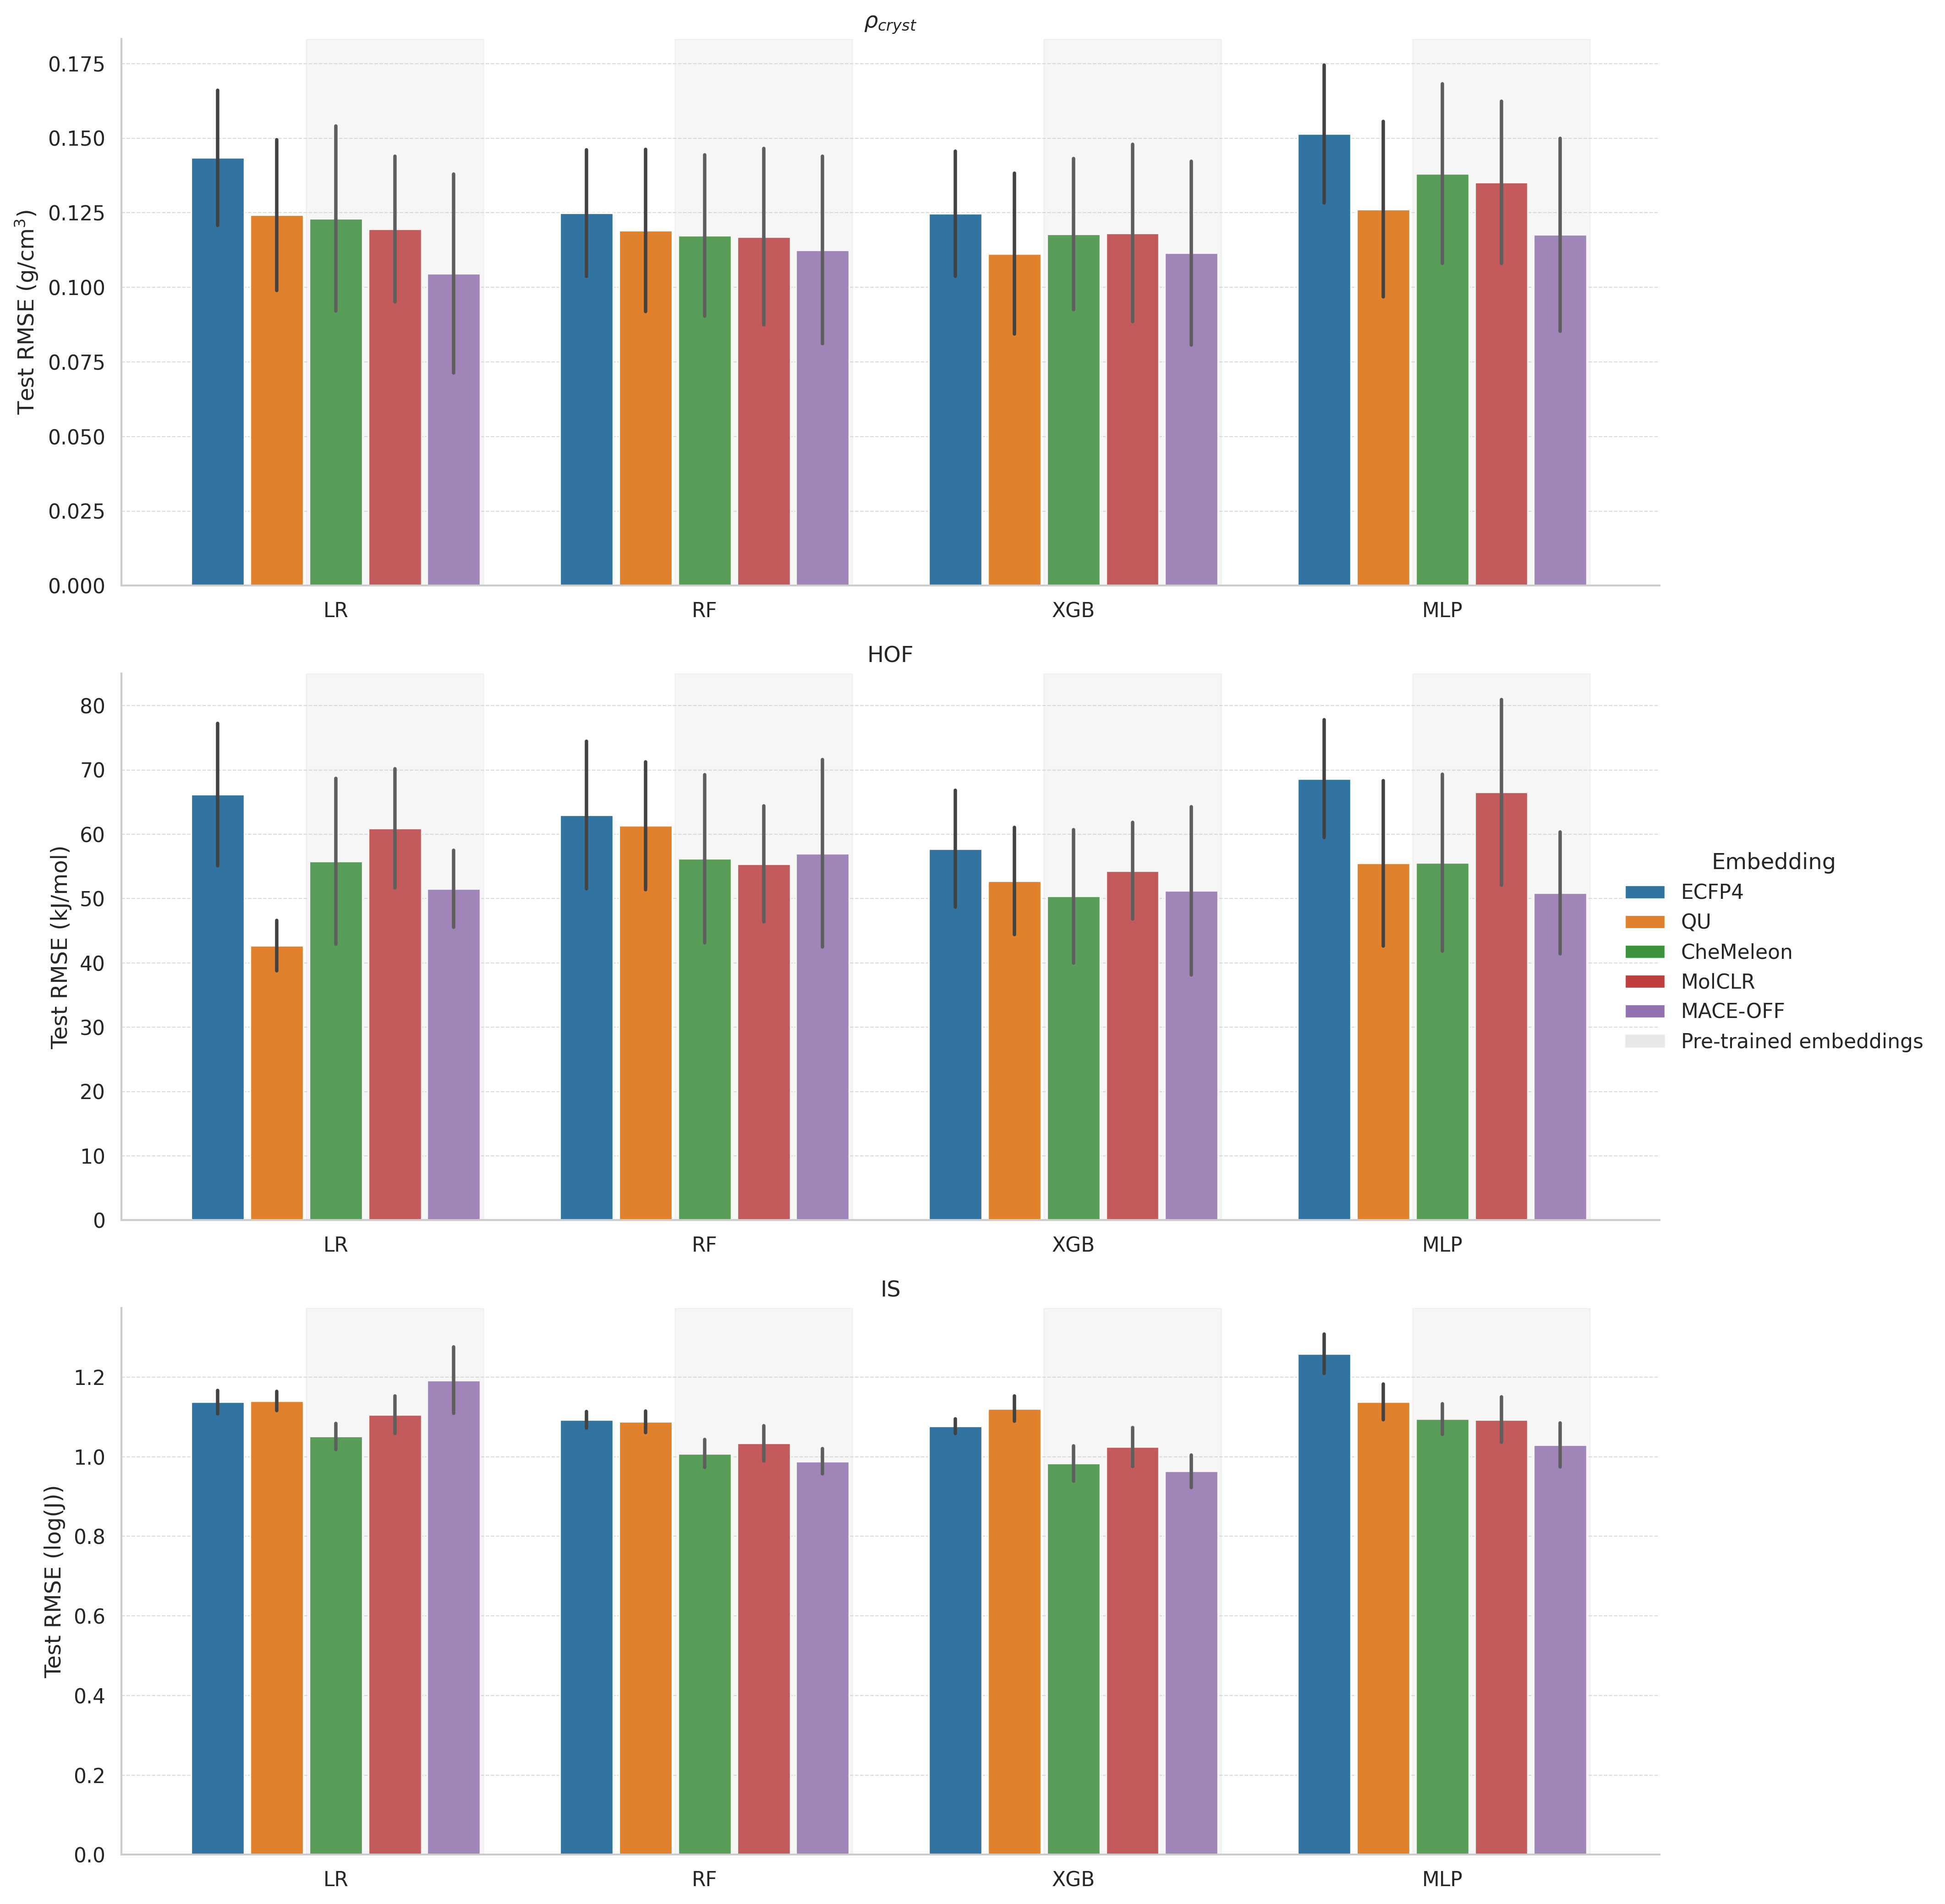

Saved 07_OUTPUTS/20260625/figures/random_split_benchmark_rmse.png


In [113]:
random_results = select_split(clean_results, "random")
display(summarise_results(random_results))
plot_benchmark_rmse(random_results, "random_split_benchmark_rmse.png");

### Are the foundation-model embeddings equal to or better than QU?

One-sided paired t-tests use matched seed/split runs after averaging across prediction heads. Lower RMSE is better.

In [114]:
display(compare_to_reference(random_results).round(3))

Paired runs  Reference mean RMSE  \
Dataset        Reference Candidate                                     
$\rho_{cryst}$ QU        ECFP4               25                0.120   
                         CheMeleon           25                0.120   
                         MolCLR              25                0.120   
                         MACE-OFF            25                0.120   
HOF            QU        ECFP4               25               53.069   
                         CheMeleon           25               53.069   
                         MolCLR              25               53.069   
                         MACE-OFF            25               53.069   
IS             QU        ECFP4               25                1.122   
                         CheMeleon           25                1.122   
                         MolCLR              25                1.122   
                         MACE-OFF            25                1.122   

                                    Candidate mean RMSE  t statistic  p value  \
Dataset        Reference Candidate                                              
$\rho_{cryst}$ QU        ECFP4                    0.136       -9.146    0.000   
                         CheMeleon                0.124       -2.527    0.009   
                         MolCLR                   0.122       -3.475    0.001   
                         MACE-OFF                 0.112        7.854    1.000   
HOF            QU        ECFP4                   63.905       -9.624    0.000   
                         CheMeleon               54.505       -1.264    0.109   
                         MolCLR                  59.297       -6.396    0.000   
                         MACE-OFF                52.663        0.345    0.633   
IS             QU        ECFP4                    1.142       -4.659    0.000   
                         CheMeleon                1.034       15.507    1.000   
                         MolCLR                   1.064        5.992    1.000   
                         MACE-OFF                 1.034       13.914    1.000   

                                                            Result  
Dataset        Reference Candidate                                  
$\rho_{cryst}$ QU        ECFP4      Reference significantly better  
                         CheMeleon  Reference significantly better  
                         MolCLR     Reference significantly better  
                         MACE-OFF        Candidate equal or better  
HOF            QU        ECFP4      Reference significantly better  
                         CheMeleon       Candidate equal or better  
                         MolCLR     Reference significantly better  
                         MACE-OFF        Candidate equal or better  
IS             QU        ECFP4      Reference significantly better  
                         CheMeleon       Candidate equal or better  
                         MolCLR          Candidate equal or better  
                         MACE-OFF        Candidate equal or better

### Comparisons with the best embedding

Each embedding is compared with the lowest-mean embedding for its dataset. Holm correction is applied within each dataset.

In [115]:
display(compare_to_best(random_results).round(3))
display(rank_embeddings(random_results))

Paired runs  Best mean RMSE  \
Dataset        Best embedding Compared embedding                                
$\rho_{cryst}$ MACE-OFF       QU                           25           0.112   
                              MolCLR                       25           0.112   
                              CheMeleon                    25           0.112   
                              ECFP4                        25           0.112   
HOF            MACE-OFF       QU                           25          52.663   
                              CheMeleon                    25          52.663   
                              MolCLR                       25          52.663   
                              ECFP4                        25          52.663   
IS             MACE-OFF       CheMeleon                    25           1.034   
                              MolCLR                       25           1.034   
                              QU                           25           1.034   
                              ECFP4                        25           1.034   

                                                  Other mean RMSE  \
Dataset        Best embedding Compared embedding                    
$\rho_{cryst}$ MACE-OFF       QU                            0.120   
                              MolCLR                        0.122   
                              CheMeleon                     0.124   
                              ECFP4                         0.136   
HOF            MACE-OFF       QU                           53.069   
                              CheMeleon                    54.505   
                              MolCLR                       59.297   
                              ECFP4                        63.905   
IS             MACE-OFF       CheMeleon                     1.034   
                              MolCLR                        1.064   
                              QU                            1.122   
                              ECFP4                         1.142   

                                                  RMSE difference  \
Dataset        Best embedding Compared embedding                    
$\rho_{cryst}$ MACE-OFF       QU                            0.009   
                              MolCLR                        0.011   
                              CheMeleon                     0.013   
                              ECFP4                         0.025   
HOF            MACE-OFF       QU                            0.406   
                              CheMeleon                     1.842   
                              MolCLR                        6.634   
                              ECFP4                        11.241   
IS             MACE-OFF       CheMeleon                     0.001   
                              MolCLR                        0.031   
                              QU                            0.088   
                              ECFP4                         0.108   

                                                  t statistic  Raw p value  \
Dataset        Best embedding Compared embedding                             
$\rho_{cryst}$ MACE-OFF       QU                       -7.854        0.000   
                              MolCLR                  -10.152        0.000   
                              CheMeleon                -6.476        0.000   
                              ECFP4                    -9.818        0.000   
HOF            MACE-OFF       QU                       -0.345        0.367   
                              CheMeleon                -1.608        0.060   
                              MolCLR                   -5.161        0.000   
                              ECFP4                   -16.428        0.000   
IS             MACE-OFF       CheMeleon                -0.132        0.448   
                              MolCLR                   -3.647        0.001   
                              QU             

,Win Count,Avg Rank
embedding,,
MACE-OFF,7,1.75
CheMeleon,2,2.50
QU,2,3.17
MolCLR,1,2.83
ECFP4,0,4.75


## Cluster splits

test_RMSE         test_R2       
                              mean     std    mean    std
dataset        embedding                                 
$\rho_{cryst}$ ECFP4         0.160   0.060   0.100  0.226
               QU            0.122   0.052   0.374  0.176
               CheMeleon     0.129   0.065   0.290  0.279
               MolCLR        0.137   0.058   0.258  0.291
               MACE-OFF      0.124   0.067   0.394  0.293
HOF            ECFP4        69.032  23.573   0.094  0.385
               QU           58.262  17.308   0.313  0.275
               CheMeleon    60.751  20.019   0.299  0.312
               MolCLR       71.118  25.771   0.137  0.384
               MACE-OFF     61.076  22.184   0.282  0.285
IS             ECFP4         1.344   0.114  -0.123  0.166
               QU            1.250   0.145   0.010  0.142
               CheMeleon     1.284   0.187  -0.047  0.191
               MolCLR        1.332   0.144  -0.131  0.150
               MACE-OFF      1.226   0.145   0.043  0.186

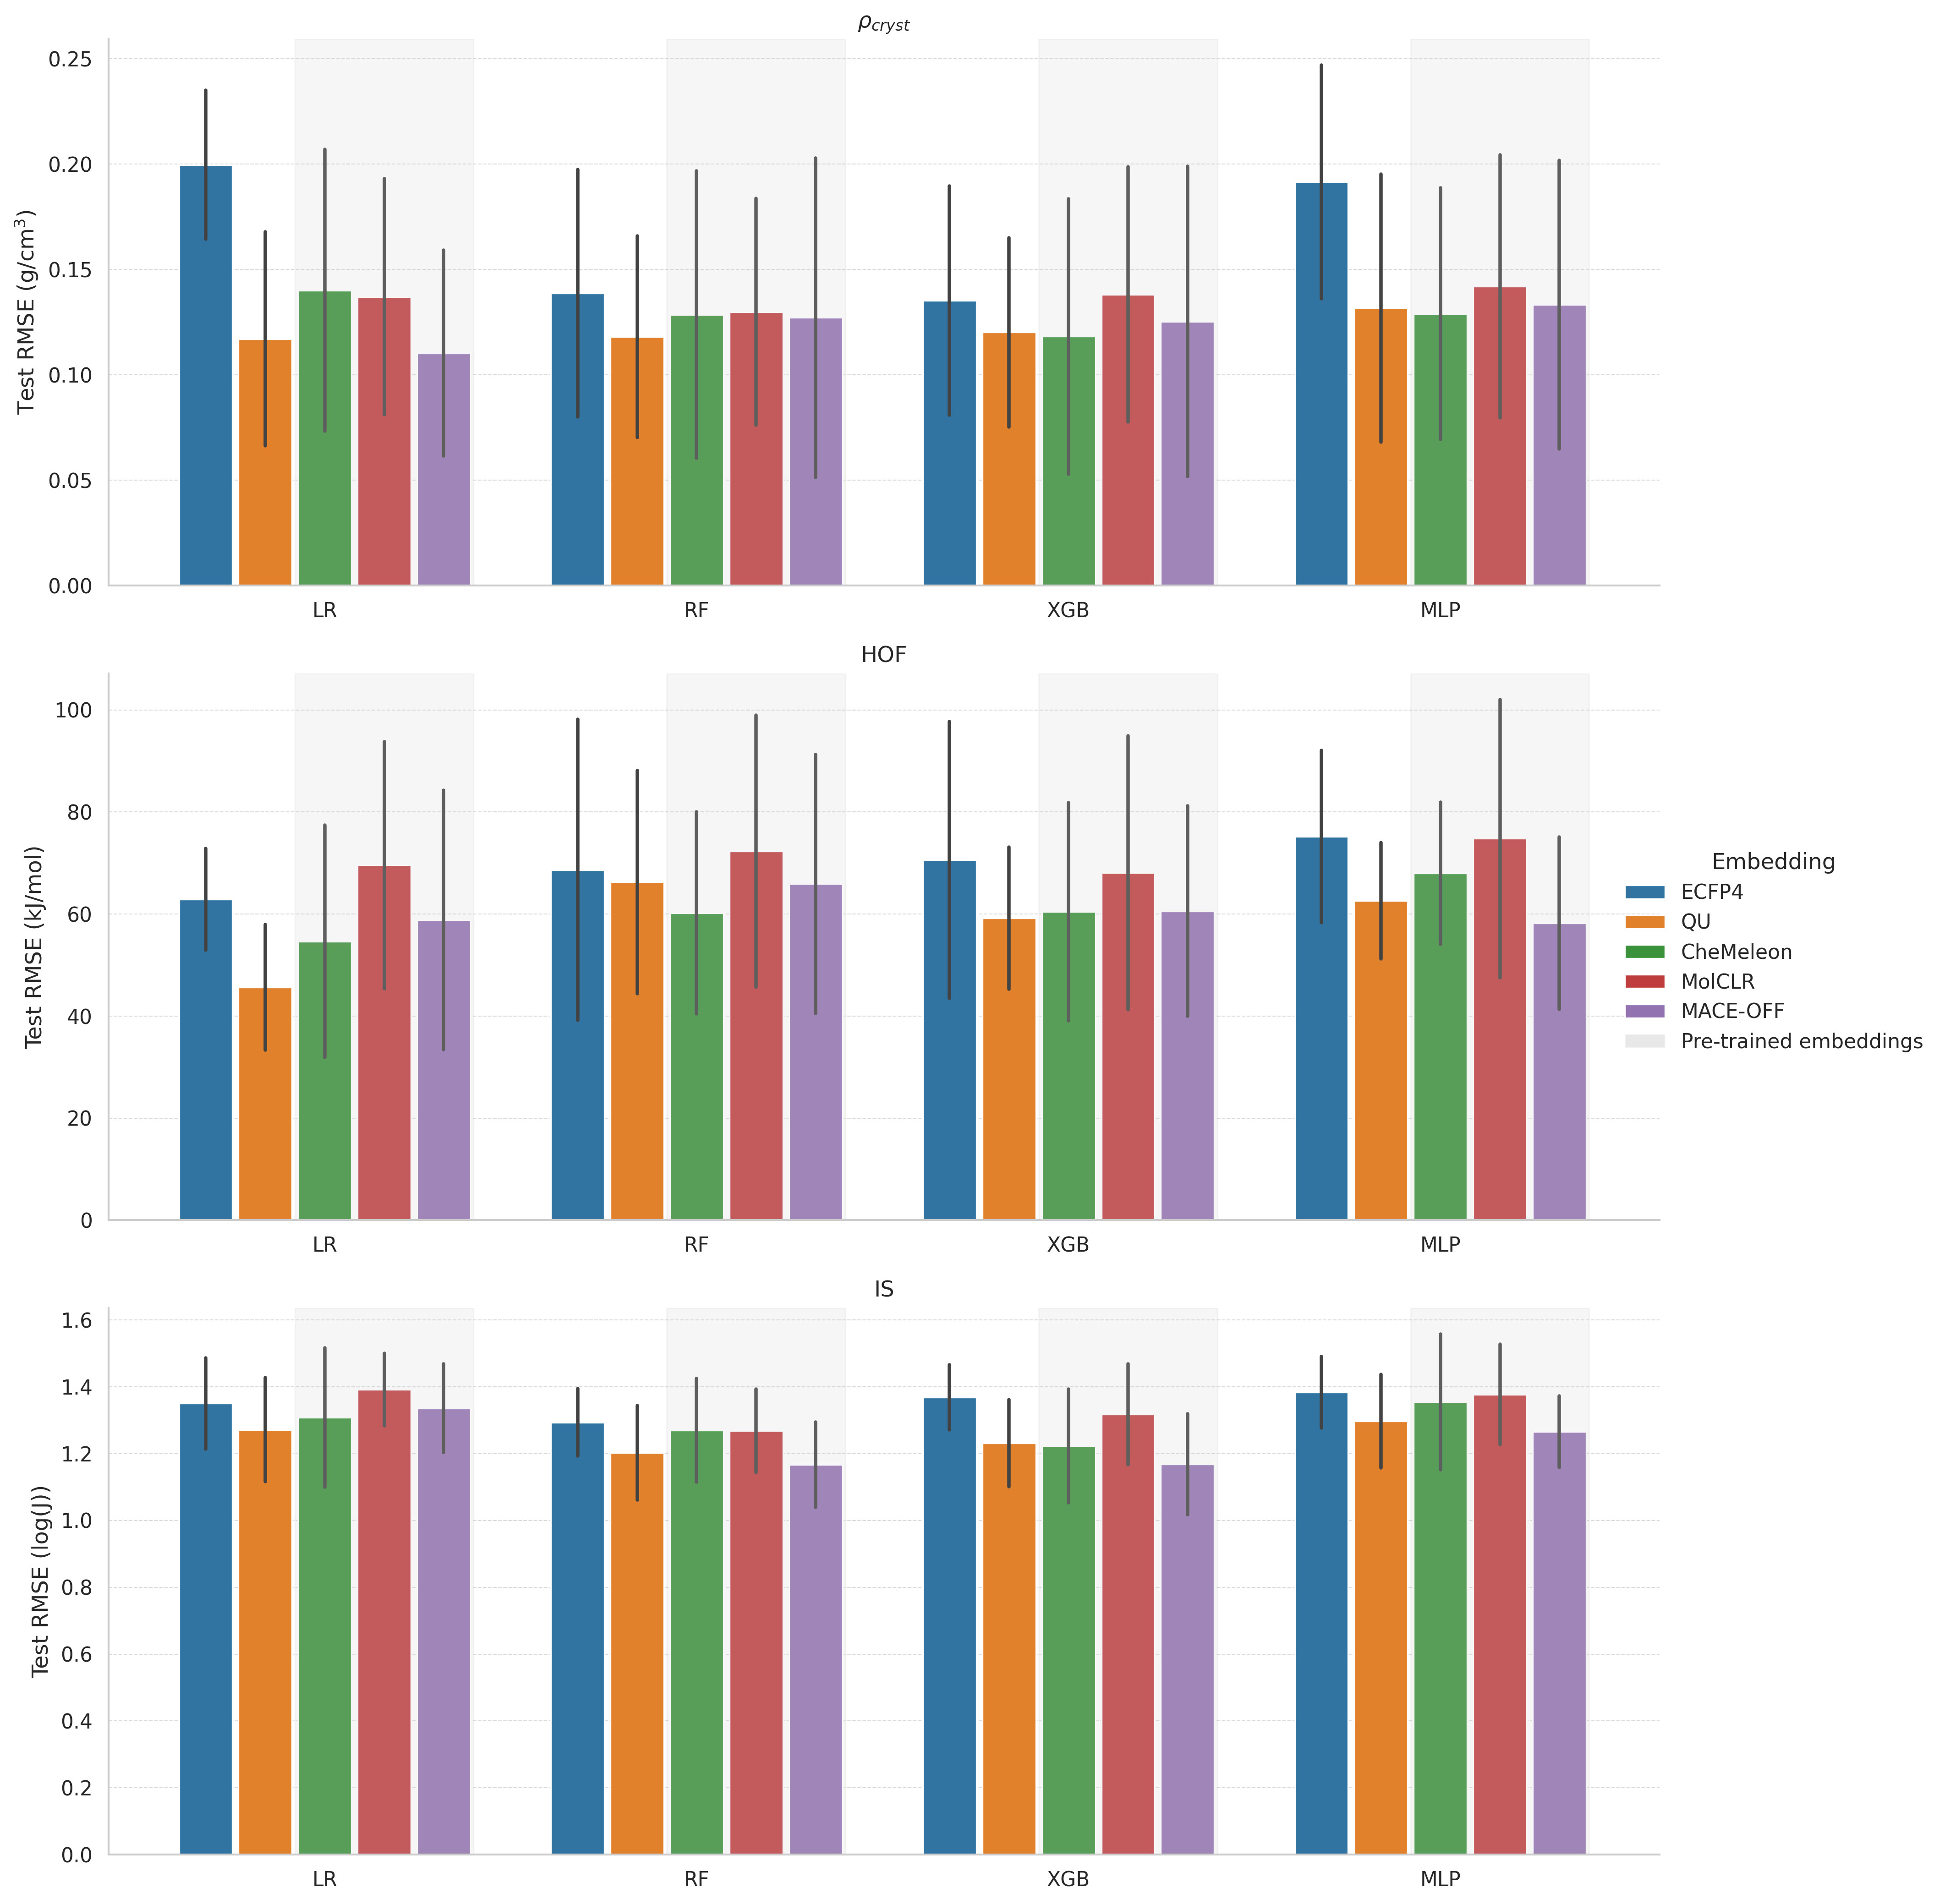

Saved 07_OUTPUTS/20260625/figures/cluster_split_benchmark_rmse.png


In [116]:
cluster_results = select_split(clean_results, "cluster")
display(summarise_results(cluster_results))
plot_benchmark_rmse(cluster_results, "cluster_split_benchmark_rmse.png");

In [117]:
display(compare_to_best(cluster_results).round(3))
display(rank_embeddings(cluster_results))

Paired runs  Best mean RMSE  \
Dataset        Best embedding Compared embedding                                
$\rho_{cryst}$ QU             MACE-OFF                     25           0.123   
                              MolCLR                       25           0.123   
                              CheMeleon                    25           0.123   
                              ECFP4                        25           0.123   
HOF            QU             CheMeleon                    25          57.582   
                              MACE-OFF                     25          57.582   
                              MolCLR                       23          58.116   
                              ECFP4                        25          57.582   
IS             MACE-OFF       QU                           25           1.230   
                              CheMeleon                    25           1.230   
                              MolCLR                       25           1.230   
                              ECFP4                        25           1.230   

                                                  Other mean RMSE  \
Dataset        Best embedding Compared embedding                    
$\rho_{cryst}$ QU             MACE-OFF                      0.124   
                              MolCLR                        0.135   
                              CheMeleon                     0.137   
                              ECFP4                         0.146   
HOF            QU             CheMeleon                    58.834   
                              MACE-OFF                     60.461   
                              MolCLR                       69.333   
                              ECFP4                        71.185   
IS             MACE-OFF       QU                            1.250   
                              CheMeleon                     1.288   
                              MolCLR                        1.327   
                              ECFP4                         1.338   

                                                  RMSE difference  \
Dataset        Best embedding Compared embedding                    
$\rho_{cryst}$ QU             MACE-OFF                      0.001   
                              MolCLR                        0.012   
                              CheMeleon                     0.013   
                              ECFP4                         0.023   
HOF            QU             CheMeleon                     1.252   
                              MACE-OFF                      2.879   
                              MolCLR                       11.217   
                              ECFP4                        13.603   
IS             MACE-OFF       QU                            0.021   
                              CheMeleon                     0.058   
                              MolCLR                        0.097   
                              ECFP4                         0.109   

                                                  t statistic  Raw p value  \
Dataset        Best embedding Compared embedding                             
$\rho_{cryst}$ QU             MACE-OFF                 -0.134        0.447   
                              MolCLR                   -3.643        0.001   
                              CheMeleon                -2.418        0.012   
                              ECFP4                    -6.996        0.000   
HOF            QU             CheMeleon                -0.865        0.198   
                              MACE-OFF                 -1.776        0.044   
                              MolCLR                   -4.622        0.000   
                              ECFP4                    -5.757        0.000   
IS             MACE-OFF       QU                       -2.393        0.012   
                              CheMeleon                -3.446        0.001   
                              MolCLR         

,Win Count,Avg Rank
embedding,,
MACE-OFF,5,2.00
QU,4,1.83
CheMeleon,3,2.33
MolCLR,0,4.17
ECFP4,0,4.67


## Penalty from harder splits

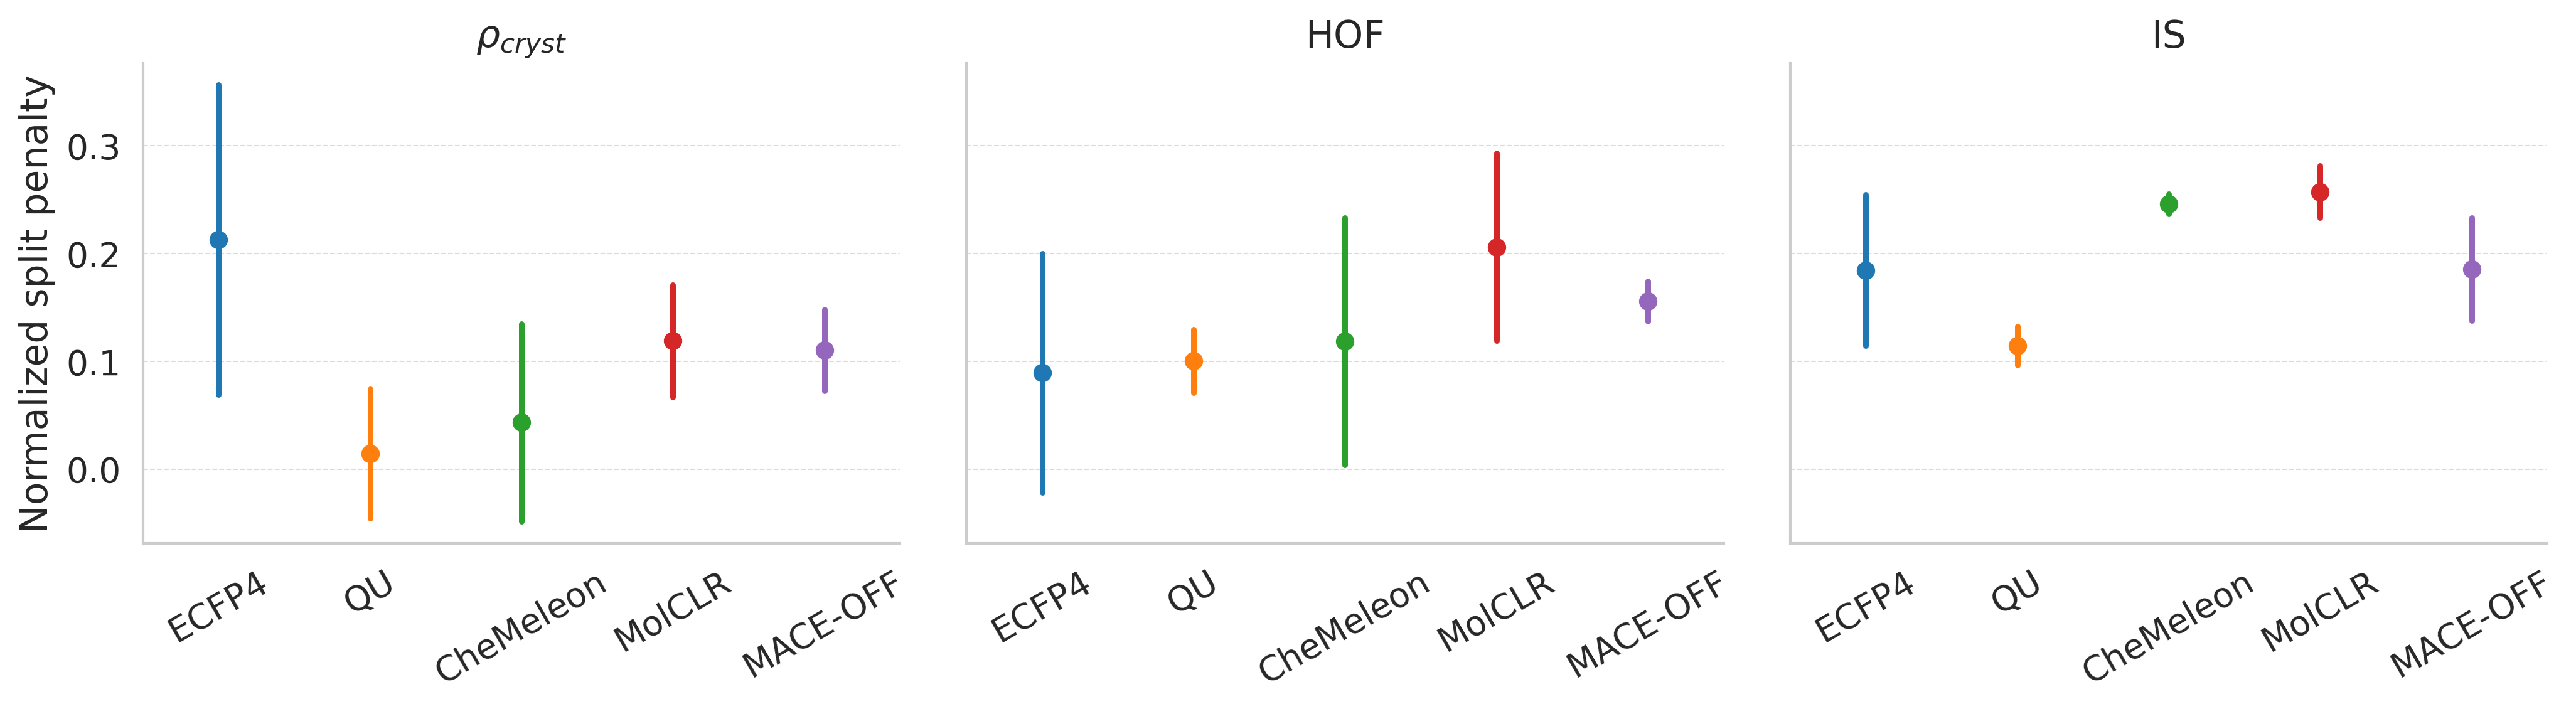

Saved 07_OUTPUTS/20260625/figures/normalized_cluster_split_penalty.png


In [118]:
def calculate_split_penalties(results: pd.DataFrame) -> pd.DataFrame:
    group_columns = ["dataset", "embedding", "model"]
    random_means = (
        select_split(results, "random_seed")
        .groupby(group_columns, as_index=False, observed=True)["test_RMSE"]
        .mean()
        .rename(columns={"test_RMSE": "random_RMSE"})
    )
    cluster_means = (
        select_split(results, "cluster")
        .groupby(group_columns, as_index=False, observed=True)["test_RMSE"]
        .mean()
        .rename(columns={"test_RMSE": "cluster_RMSE"})
    )
    penalties = random_means.merge(cluster_means, on=group_columns, how="inner")
    penalties["normalized_split_penalty"] = (
        penalties["cluster_RMSE"] - penalties["random_RMSE"]
    ) / penalties["random_RMSE"]
    return penalties


def plot_split_penalties(penalties: pd.DataFrame) -> plt.Figure:
    sns.set_theme(style="whitegrid", context="paper", font_scale=1.5)
    fig, axes = plt.subplots(1, len(DATASET_ORDER), figsize=(14, 4), sharey=True, dpi=300)

    for ax, dataset in zip(np.atleast_1d(axes), DATASET_ORDER):
        subset = penalties.loc[penalties["dataset"] == dataset]
        sns.pointplot(
            data=subset,
            x="embedding",
            y="normalized_split_penalty",
            hue="embedding",
            order=EMBEDDING_ORDER,
            palette=sns.color_palette("tab10", n_colors=len(EMBEDDING_ORDER)),
            errorbar="sd",
            markers="o",
            linestyles="none",
            legend=False,
            ax=ax,
        )
        ax.set(
            title=str(dataset),
            xlabel="",
            ylabel="Normalized split penalty" if ax is axes[0] else "",
        )
        ax.tick_params(axis="x", rotation=30)
        ax.grid(axis="y", linestyle="--", linewidth=0.5, alpha=0.7)
        sns.despine(ax=ax)

    fig.tight_layout()
    save_figure(fig, "normalized_cluster_split_penalty.png")
    return fig


split_penalties = calculate_split_penalties(df)
plot_split_penalties(split_penalties);

In [119]:
display(
    split_penalties.groupby(["dataset", "embedding"], observed=True)
    [["normalized_split_penalty"]]
    .agg(["mean", "std"])
    .round(3)
)

normalized_split_penalty       
                                             mean    std
dataset        embedding                                
$\rho_{cryst}$ ECFP4                        0.213  0.144
               QU                           0.014  0.060
               CheMeleon                    0.043  0.092
               MolCLR                       0.119  0.052
               MACE-OFF                     0.111  0.038
HOF            ECFP4                        0.089  0.111
               QU                           0.100  0.030
               CheMeleon                    0.119  0.115
               MolCLR                       0.206  0.087
               MACE-OFF                     0.156  0.019
IS             ECFP4                        0.185  0.070
               QU                           0.114  0.018
               CheMeleon                    0.246  0.009
               MolCLR                       0.257  0.024
               MACE-OFF                     0.186  0.048

## Impact of the prediction head

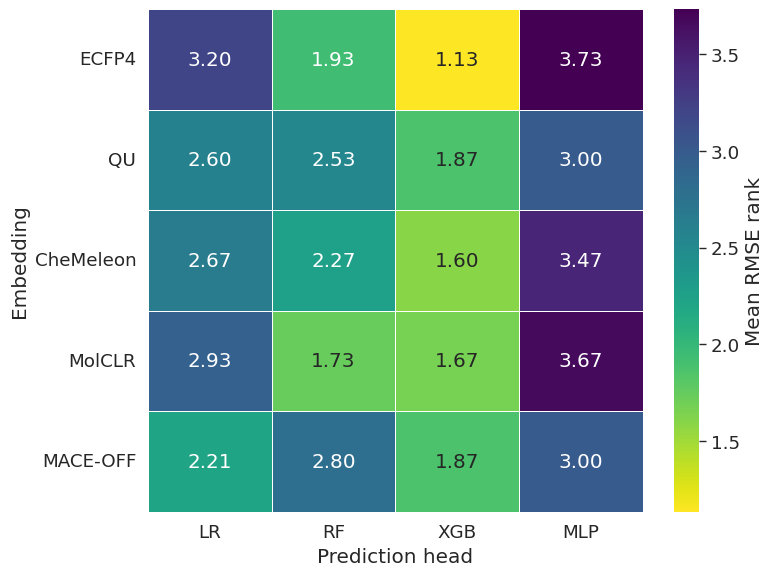

Saved 07_OUTPUTS/20260625/figures/prediction_head_mean_rmse_rank.png


In [120]:
def plot_prediction_head_ranks(results: pd.DataFrame) -> plt.Figure:
    summary = (
        results.groupby(
            ["dataset", "embedding", "model", "split_method"],
            as_index=False,
            observed=True,
        )["test_RMSE"]
        .agg(mean_RMSE="mean")
    )
    summary["rank"] = summary.groupby(
        ["dataset", "embedding", "split_method"], observed=True
    )["mean_RMSE"].rank(method="dense", ascending=True)

    heatmap_data = (
        summary.groupby(["embedding", "model"], observed=True)["rank"]
        .mean()
        .unstack("model")
        .reindex(index=EMBEDDING_ORDER, columns=MODEL_ORDER)
    )

    fig, ax = plt.subplots(figsize=(8, 6))
    sns.heatmap(
        heatmap_data,
        annot=True,
        fmt=".2f",
        cmap="viridis_r",
        linewidths=0.5,
        cbar_kws={"label": "Mean RMSE rank"},
        ax=ax,
    )
    ax.set(xlabel="Prediction head", ylabel="Embedding")
    ax.tick_params(axis="both", rotation=0)
    fig.tight_layout()
    save_figure(fig, "prediction_head_mean_rmse_rank.png")
    return fig


plot_prediction_head_ranks(random_results);

## Prediction parity and residuals

In [121]:
prediction_script = REPO_ROOT / "05_PY_SCRIPTS" / "generate_xgb_predictions.py"
subprocess.run([sys.executable, str(prediction_script)], check=True)

predictions_path = REPO_ROOT / "deep_dive_xgb_predictions.parquet"
predictions_df = pd.read_parquet(predictions_path)
predictions_df["embedding"] = predictions_df["embedding"].replace(EMBEDDING_LABELS)
predictions_df["dataset"] = predictions_df["dataset"].replace(DATASET_LABELS)
predictions_df["dataset"] = pd.Categorical(
    predictions_df["dataset"], categories=DATASET_ORDER, ordered=True
)
predictions_df.head()

/home/andre/anaconda3/envs/chem/lib/python3.11/site-packages/xgboost/core.py:377: FutureWarning: Your system has an old version of glibc (< 2.28). We will stop supporting Linux distros with glibc older than 2.28 after **May 31, 2025**. Please upgrade to a recent Linux distro (with glibc >= 2.28) to use future versions of XGBoost.
Note: You have installed the 'manylinux2014' variant of XGBoost. Certain features such as GPU algorithms or federated learning are not available. To use these features, please upgrade to a recent Linux distro with glibc 2.28+, and install the 'manylinux_2_28' variant.
  warnings.warn(


Processed CD/xgboost/hq_descriptor/split=random_seed0_modelseed=0/ckpts/hq_descriptor_model=xgboost_seed=0.pkl
Processed CD/xgboost/hq_descriptor/split=random_seed0_modelseed=1/ckpts/hq_descriptor_model=xgboost_seed=1.pkl
Processed CD/xgboost/hq_descriptor/split=random_seed0_modelseed=2/ckpts/hq_descriptor_model=xgboost_seed=2.pkl
Processed CD/xgboost/hq_descriptor/split=random_seed0_modelseed=3/ckpts/hq_descriptor_model=xgboost_seed=3.pkl
Processed CD/xgboost/hq_descriptor/split=random_seed0_modelseed=4/ckpts/hq_descriptor_model=xgboost_seed=4.pkl
Processed CD/xgboost/hq_descriptor/split=random_seed1_modelseed=0/ckpts/hq_descriptor_model=xgboost_seed=0.pkl
Processed CD/xgboost/hq_descriptor/split=random_seed1_modelseed=1/ckpts/hq_descriptor_model=xgboost_seed=1.pkl
Processed CD/xgboost/hq_descriptor/split=random_seed1_modelseed=2/ckpts/hq_descriptor_model=xgboost_seed=2.pkl
Processed CD/xgboost/hq_descriptor/split=random_seed1_modelseed=3/ckpts/hq_descriptor_model=xgboost_seed=3.pkl
P

,dataset,embedding,split_seed,model_seed,compound_id,y_true,y_pred
0,$\rho_{cryst}$,QU,0,0,O=C(OCC([N+](=O)[O-])([N+](=O)[O-])[N+](=O)[O-...,1.851,1.833033
1,$\rho_{cryst}$,QU,0,0,O=C(CCN(CCC(=O)OCC([N+](=O)[O-])([N+](=O)[O-])...,1.703,1.706970
2,$\rho_{cryst}$,QU,0,0,O=[N+]([O-])c1cc([N+](=O)[O-])c(-c2c([N+](=O)[...,1.828,1.738453
3,$\rho_{cryst}$,QU,0,0,O=[N+]([O-])c1ccc(CC([N+](=O)[O-])([N+](=O)[O-...,1.732,1.705867
4,$\rho_{cryst}$,QU,0,0,Cn1nc([N+](=O)[O-])c(Nc2c([N+](=O)[O-])cc([N+]...,1.746,1.755874


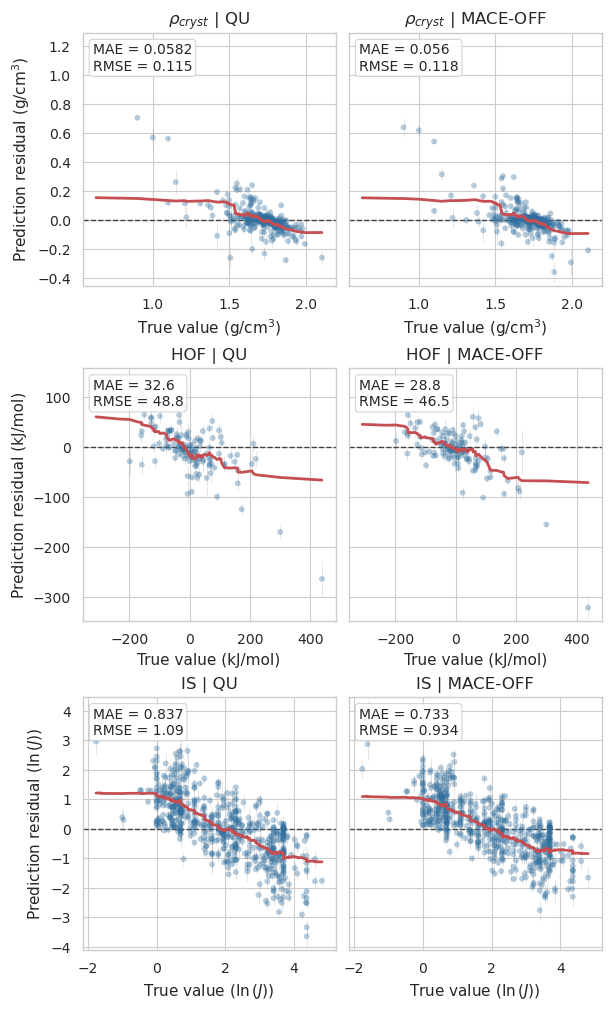

Saved 07_OUTPUTS/20260625/figures/xgb_prediction_residuals.png


In [122]:
fig = plot_residual_grid(
    predictions_df,
    embeddings=["QU", "MACE-OFF"],
    show_pred_std=True,
    use_aggregated=True,
    figsize=(6, 10),
)
save_figure(fig, "xgb_prediction_residuals.png");

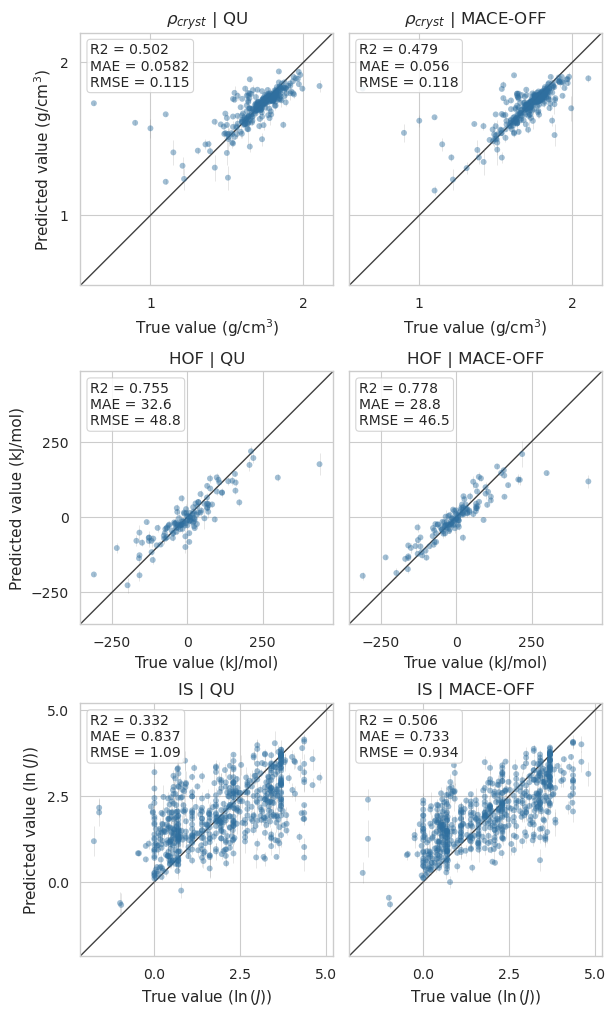

Saved 07_OUTPUTS/20260625/figures/xgb_prediction_parity.png


In [123]:
fig = plot_parity_grid(
    predictions_df,
    embeddings=["QU", "MACE-OFF"],
    use_aggregated=True,
    color_by=None,
    show_pred_std=True,
    figsize=(6, 10),
)
save_figure(fig, "xgb_prediction_parity.png");